# APARTMENT RENT PREDICTOR
Predicción del precio de alquiler por superficie(m2) de viviendas en Estados Unidos mediante Machine Learning.

## 1. Exploracion de datos

**Fuente:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/555/apartment+for+rent+classified)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
apartments = pd.read_csv("../data/raw/apartments_for_rent_classified_10K.csv", sep=";", encoding="cp1252")
apartments.head()

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668626895,housing/rent/apartment,"Studio apartment 2nd St NE, Uhland Terrace NE,...","This unit is located at second St NE, Uhland T...",NaN,NaN,0.0,USD,No,Thumbnail,...,$790,Monthly,101,NaN,Washington,DC,38.9057,-76.9861,RentLingo,1577359415
1,5664597177,housing/rent/apartment,Studio apartment 814 Schutte Road,"This unit is located at 814 Schutte Road, Evan...",NaN,NaN,1.0,USD,No,Thumbnail,...,$425,Monthly,106,814 Schutte Rd,Evansville,IN,37.9680,-87.6621,RentLingo,1577017063
2,5668626833,housing/rent/apartment,"Studio apartment N Scott St, 14th St N, Arling...","This unit is located at N Scott St, 14th St N,...",NaN,1.0,0.0,USD,No,Thumbnail,...,"$1,390",Monthly,107,NaN,Arlington,VA,38.8910,-77.0816,RentLingo,1577359410
3,5659918074,housing/rent/apartment,Studio apartment 1717 12th Ave,"This unit is located at 1717 12th Ave, Seattle...",NaN,1.0,0.0,USD,No,Thumbnail,...,$925,Monthly,116,1717 12th Avenue,Seattle,WA,47.6160,-122.3275,RentLingo,1576667743
4,5668626759,housing/rent/apartment,"Studio apartment Washington Blvd, N Cleveland ...","This unit is located at Washington Blvd, N Cle...",NaN,NaN,0.0,USD,No,Thumbnail,...,$880,Monthly,125,NaN,Arlington,VA,38.8738,-77.1055,RentLingo,1577359401


In [3]:
apartments.shape

(10000, 22)

In [4]:
apartments.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             10000 non-null  int64  
 1   category       10000 non-null  str    
 2   title          10000 non-null  str    
 3   body           10000 non-null  str    
 4   amenities      6451 non-null   str    
 5   bathrooms      9966 non-null   float64
 6   bedrooms       9993 non-null   float64
 7   currency       10000 non-null  str    
 8   fee            10000 non-null  str    
 9   has_photo      10000 non-null  str    
 10  pets_allowed   5837 non-null   str    
 11  price          10000 non-null  int64  
 12  price_display  10000 non-null  str    
 13  price_type     10000 non-null  str    
 14  square_feet    10000 non-null  int64  
 15  address        6673 non-null   str    
 16  cityname       9923 non-null   str    
 17  state          9923 non-null   str    
 18  latitude       999

In [5]:
apartments.isnull().sum()

id                  0
category            0
title               0
body                0
amenities        3549
bathrooms          34
bedrooms            7
currency            0
fee                 0
has_photo           0
pets_allowed     4163
price               0
price_display       0
price_type          0
square_feet         0
address          3327
cityname           77
state              77
latitude           10
longitude          10
source              0
time                0
dtype: int64

In [6]:
(apartments.isnull().mean() * 100).round(1).sort_values(ascending=False)

pets_allowed     41.6
amenities        35.5
address          33.3
cityname          0.8
state             0.8
bathrooms         0.3
latitude          0.1
bedrooms          0.1
longitude         0.1
category          0.0
title             0.0
body              0.0
id                0.0
fee               0.0
price_type        0.0
price_display     0.0
price             0.0
has_photo         0.0
currency          0.0
square_feet       0.0
source            0.0
time              0.0
dtype: float64

- hay 3 columnas: "pets_allowed 41.6% ","amenities 35.5% " y "address 33.3% " (muchos casos NULOS), mientras que "cityname" 0.8%, "state" 0.8% (pocos casos NULOS), "bathrooms", "latitude". "bedrooms", "longitude"(MUY POCOS CASOS 0.3% Y 0.1%). Al final de la exploracion hay que decidir que hacemos con ellos

In [7]:
apartments.describe()

,id,bathrooms,bedrooms,price,square_feet,latitude,longitude,time
count,1.000000e+04,9966.000000,9993.000000,10000.000000,10000.000000,9990.000000,9990.000000,1.000000e+04
mean,5.623396e+09,1.380544,1.744021,1486.277500,945.810500,37.695162,-94.652247,1.574891e+09
std,7.021025e+07,0.615410,0.942354,1076.507968,655.755736,5.495851,15.759805,3.762395e+06
min,5.508654e+09,1.000000,0.000000,200.000000,101.000000,21.315500,-158.022100,1.568744e+09
25%,5.509248e+09,1.000000,1.000000,949.000000,649.000000,33.679850,-101.301700,1.568781e+09
50%,5.668610e+09,1.000000,2.000000,1270.000000,802.000000,38.809800,-93.651600,1.577358e+09
75%,5.668626e+09,2.000000,2.000000,1695.000000,1100.000000,41.349800,-82.209975,1.577359e+09
max,5.668663e+09,8.500000,9.000000,52500.000000,40000.000000,61.594000,-70.191600,1.577362e+09


hay valores sospechosos
- price: el mínimo es 200 $ y el máximo 52.500 $ al mes. Ese máximo es casi seguro un error o un caso extremo (outlier).
- square_feet: el mínimo es 101 pies² (unos 9 m², muy pequeño) y el máximo 40.000 pies² (unos 3.700 m²). Un piso así no es realista.
- La media del precio 1.486 $ es mayor que la mediana 1.270 $. Eso indica que hay algunos precios muy altos que “tiran” de la media hacia arriba. Es típico en precios inmobiliarios.
- bedrooms = 0 no es un error: son estudios (studio apartment), como se ve en head().
- time es una fecha en formato Unix (segundos desde 1970). Va más o menos de septiembre a diciembre de 2019, solo unos 3 meses, así que seguramente aportará poco.

In [8]:
apartments.nunique()

id               10000
category             3
title             9350
body              9961
amenities         2254
bathrooms           14
bedrooms            10
currency             1
fee                  1
has_photo            3
pets_allowed         3
price             1725
price_display     1726
price_type           3
square_feet       1738
address           6658
cityname          1574
state               51
latitude          2395
longitude         2392
source              12
time              6310
dtype: int64

Observaciones:
- 'currency' y 'fee' tienen un único valor, por lo que no aportan información.
- 'amenities' (2.254 combinaciones) y 'cityname' (1.574 ciudades), requerirán un tratamiento específico.

In [9]:
for column in ["category", "currency", "fee", "price_type", "has_photo", "pets_allowed", "source"]:
    print(apartments[column].value_counts(dropna=False), "\n")

category
housing/rent/apartment     9996
housing/rent/home             2
housing/rent/short_term       2
Name: count, dtype: int64 

currency
USD    10000
Name: count, dtype: int64 

fee
No    10000
Name: count, dtype: int64 

price_type
Monthly           9998
Weekly               1
Monthly|Weekly       1
Name: count, dtype: int64 

has_photo
Thumbnail    8907
Yes           909
No            184
Name: count, dtype: int64 

pets_allowed
Cats,Dogs    5228
NaN          4163
Cats          485
Dogs          124
Name: count, dtype: int64 

source
RentLingo            6912
RentDigs.com         2764
ListedBuy             179
RealRentals            69
GoSection8             31
Listanza               23
RENTOCULAR             16
rentbits                2
Home Rentals            1
Real Estate Agent       1
RENTCafé                1
tenantcloud             1
Name: count, dtype: int64 



Observaciones:
- casi todos los anuncios son apartamentos con precio mensual; se descartarán los 4 inmuebles de otro tipo y los 2 precios semanales para trabajar con datos homogéneos.
- 'has_photo' se conserva como posible indicador de la calidad del anuncio.
- 'pets_allowed' no existe el valor "No", por lo que los nulos (4163) se interpretarán como "no indicado".
- 'source' se descartará al no ser una característica del inmueble (casi toda la meustra procede de solo dos portales).

In [10]:
apartments["amenities"].head(10)

0                                            NaN
1                                            NaN
2                                            NaN
3                                            NaN
4                                            NaN
5    Dishwasher,Elevator,Patio/Deck,Pool,Storage
6                                            NaN
7                                            NaN
8                                   Refrigerator
9                                            NaN
Name: amenities, dtype: str

- 'amenities': contiene listas de servicios separados por comas (gimnasio, piscina, ascensor...). Se transformará en variables individuales para medir el impacto de cada servicio en el precio.

In [11]:
apartments["amenities"].str.split(",").explode().value_counts()

amenities
Parking               3727
Dishwasher            3266
Pool                  3238
Refrigerator          3133
Patio/Deck            2472
Cable or Satellite    1678
Storage               1531
Gym                   1469
Internet Access       1441
Clubhouse             1317
Garbage Disposal      1210
Washer Dryer          1077
Fireplace             1065
Playground             782
AC                     662
Elevator               642
Tennis                 482
Gated                  473
Wood Floors            357
Hot Tub                346
Basketball             318
TV                     207
View                   149
Doorman                 29
Alarm                   23
Golf                    23
Luxury                  11
Name: count, dtype: int64

Observaciones:
- existen 27 servicios distintos
- los más frecuentes son parking, lavavajillas, piscina, refrigerador. Algunos (portero, alarma, golf, luxury) aparecen en menos de 30 anuncios y podrían agruparse o descartarse.

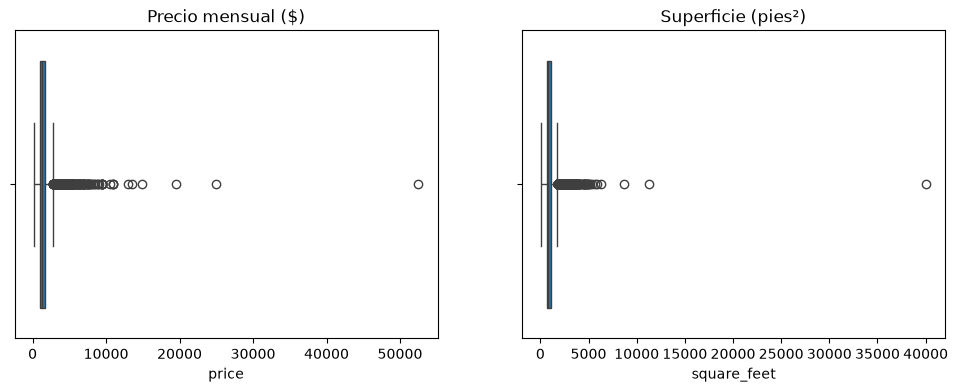

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=apartments["price"], ax=axes[0])
axes[0].set_title("Precio mensual ($)")

sns.boxplot(x=apartments["square_feet"], ax=axes[1])
axes[1].set_title("Superficie (pies²)")

plt.show()

- la mayoría de los anuncios se concentra en valores bajos-medios. Existen outliers aislados muy extremos (precio de 52.500 $, superficie de 40.000 pies²) que podrían ser errores, frente a un grupo amplio de valores altos que probablemente corresponden a pisos de gama alta reales.

In [13]:
apartments[["price", "square_feet", "bedrooms", "cityname", "state"]].sort_values("price", ascending=False).head(10)

,price,square_feet,bedrooms,cityname,state
8829,52500,1418,0.0,Barstow,CA
9996,25000,8716,6.0,Montecito,CA
9990,19500,5000,4.0,Los Angeles,CA
9972,14950,4044,6.0,Los Angeles,CA
8581,13500,1325,2.0,Los Angeles,CA
9825,13000,2530,3.0,Los Angeles,CA
9997,11000,11318,6.0,Potomac,MD
8573,11000,1322,2.0,Coronado,CA
9946,11000,3395,5.0,Hollywood,FL
9227,10600,1636,2.0,Los Angeles,CA


- la mayoría de los precios más altos corresponden a viviendas grandes en zonas exclusivas (Montecito, Los Ángeles, Potomac), por lo que se consideran reales. El caso de Barstow (52.500 $ por un estudio) es un error evidente y se eliminará.

In [14]:
apartments[["price", "square_feet", "bedrooms", "bathrooms", "cityname", "state"]].sort_values("square_feet", ascending=False).head(10)

,price,square_feet,bedrooms,bathrooms,cityname,state
9998,4790,40000,1.0,NaN,New York,NY
9997,11000,11318,6.0,8.5,Potomac,MD
9996,25000,8716,6.0,8.0,Montecito,CA
9995,6000,6300,5.0,4.0,Edina,MN
9994,3000,5921,6.0,4.0,Saint George,UT
9993,6900,5700,5.0,5.0,Lutz,FL
9992,4500,5407,4.0,5.0,Eden Prairie,MN
9991,3200,5199,6.0,5.0,Fayetteville,GA
9990,19500,5000,4.0,5.0,Los Angeles,CA
9989,3980,4970,5.0,3.5,Arvada,CO


- el registro de 40.000 pies² con 1 dormitorio (Nueva York) es un error evidente y se eliminará. El resto son viviendas grandes reales. Viviendas de tamaño similar varían de 3.000 $ (Saint George, UT) a 19.500 $ (Los Ángeles, CA), lo que indica que la ubicación será una variable clave.

In [15]:
apartments["state"].value_counts().head(15)

state
TX    1737
CA     955
WA     519
NC     438
MD     424
NJ     383
GA     372
FL     339
OH     321
CO     318
WI     302
IL     282
IN     239
MO     239
MN     221
Name: count, dtype: int64

- Texas domina con 1.737 anuncios (17% del total), seguido de California con 955. Entre los dos suman más de una cuarta parte del dataset.
- A partir de ahí la distribución baja poco a poco. Nueva York ni siquiera aparece entre los 15 primeros, y es una de las ciudades principales de EEUU
-  El dataset no es una muestra equilibrada de Estados Unidos.
- Hay 51 estados, y los que están al final de la lista tendrán muy pocos anuncios.

Esto tiene una consecuencia práctica: el modelo aprenderá muy bien los precios de Texas y California, y peor los de estados con pocos datos. Es una limitación que conviene mencionaR. "EL MODELO SERA MAS FIABLE EN LOS ESTADOS CON MAS DATOS".

In [16]:
apartments["time"]

0       1577359415
1       1577017063
2       1577359410
3       1576667743
4       1577359401
           ...    
9995    1575112975
9996    1577360419
9997    1577360560
9998    1577362186
9999    1577362141
Name: time, Length: 10000, dtype: int64

Documentación: es una fecha de creación del anuncio.
Tipo de dato: es un número entero, no una fecha legible.
Forma del número: 10 cifras que empiezan por 15, lo que encaja con formato Unix en segundos.
Comprobación: convertirlo y ver si salen fechas de 2019.

In [17]:
dates = pd.to_datetime(apartments["time"], unit="s")
print("Primera fecha:", dates.min())
print("Última fecha:", dates.max())

Primera fecha: 2019-09-17 18:12:56
Última fecha: 2019-12-26 12:09:46


In [18]:
dates.dt.to_period("M").value_counts().sort_index()

time
2019-09    2719
2019-10      15
2019-11      29
2019-12    7237
Freq: M, Name: count, dtype: int64

- Esta celda es para saber cuantos anuncios hay por mes.

Observaciones:
- se confirma el formato Unix.
- Los anuncios abarcan de septiembre a diciembre de 2019, concentrados en dos periodos de recogida (septiembre y diciembre).
- 'time' se descartará al no aportar información sobre el inmueble. El modelo reflejará precios de 2019, previos a la pandemia.

### Conclusiones de la exploración

- **Target:** precio de alquiler por m², calculado a partir de `price` y `square_feet`.
- **Columnas a eliminar:** `id`, `title`, `body`, `price_display` (data leakage), `address`, `currency`, `fee`, `source`, `category` y `price_type` (tras filtrar).
- **Filtrado:** conservar solo apartamentos con precio mensual.
- **Transformaciones:** separar `amenities` en variables individuales, convertir `pets_allowed` en dos variables binarias y pasar la superficie a m².
- **Pendiente:** tratar los outliers de `price` y `square_feet`, decidir cómo usar la ubicación (`cityname`, `state`, coordenadas).

## 2. Limpieza de datos

- filtrar apartamentos con precio mensual

In [19]:
apartments = apartments[
    (apartments["category"] == "housing/rent/apartment") &
    (apartments["price_type"] == "Monthly")]
apartments.shape

(9994, 22)

- eliminar los dos errores evidentes
- Esto elimina el estudio de Barstow (52.500 $) y el piso de 40.000 pies² de Nueva York.

In [20]:
apartments = apartments[(apartments["price"] < 50000) & (apartments["square_feet"] < 40000)]
apartments.shape

(9992, 22)

- eliminar columnas que no sirven

In [21]:
columns_to_drop = ["id", "title", "body", "price_display", "address", "currency",
                   "fee", "source", "category", "price_type", "time"]
apartments = apartments.drop(columns=columns_to_drop)
apartments.shape

(9992, 11)

- eliminar las pocas filas con nulos en columnas clave

In [22]:
apartments = apartments.dropna(subset=["bathrooms", "bedrooms", "latitude", "longitude", "cityname", "state"])
apartments.shape

(9878, 11)

subset le dice a dropna() que solo mire estas columnas. Así no se borran las filas con nulos en amenities o pets_allowed, que trataremos de otra forma.

- mascotas en dos columnas binarias

In [23]:
apartments["cats_allowed"] = apartments["pets_allowed"].str.contains("Cats", na=False).astype(int)
apartments["dogs_allowed"] = apartments["pets_allowed"].str.contains("Dogs", na=False).astype(int)
apartments = apartments.drop(columns="pets_allowed")

str.contains("Cats") comprueba si el texto incluye “Cats”. na=False hace que los nulos cuenten como “no”, tal como decidimos.

- servicios en columnas individuales

In [24]:
amenities_dummies = apartments["amenities"].fillna("").str.get_dummies(sep=",")
apartments = pd.concat([apartments, amenities_dummies], axis=1)
apartments["amenities_count"] = amenities_dummies.sum(axis=1)
apartments = apartments.drop(columns="amenities")

- fillna("") rellena los 3.549 nulos con un texto vacío. Es decir, “este anuncio no menciona servicios”.
- get_dummies crea las columnas de servicios. Para esos anuncios, como no hay ningún servicio en el texto, pone 0 en todas, y amenities_count vale 0.
- Después eliminamos la columna original amenities, que era la que tenía los nulos.

- foto : Si el anuncio tiene foto (normal o miniatura), vale 1; si no tiene, vale 0.

In [25]:
apartments["has_photo"] = (apartments["has_photo"] != "No").astype(int)

- superficie en m² y target

In [26]:
apartments["area_m2"] = apartments["square_feet"] * 0.092903
apartments["price_per_m2"] = apartments["price"] / apartments["area_m2"]
apartments = apartments.drop(columns="square_feet")
apartments[["price", "area_m2", "price_per_m2"]].describe()

,price,area_m2,price_per_m2
count,9878.000000,9878.000000,9878.000000
mean,1482.072586,87.636243,18.868744
std,948.809998,48.979568,10.761671
min,200.000000,9.940621,2.090553
25%,949.000000,60.386950,11.885644
50%,1275.000000,74.601109,16.136183
75%,1695.000000,102.193300,22.543363
max,25000.000000,1051.476154,204.928383


Observaciones:
- tras la limpieza quedan 9.878 anuncios (se conserva el 98,8%). 
- El precio mediano es de 16,1 $/m² al mes, un valor coherente con el mercado estadounidense de 2019.
- Algunos extremos (205 $/m²) se revisarán en la fase de feature engineering.

In [27]:
print(apartments.isnull().sum().sum())
apartments.shape

0


(9878, 41)

In [28]:
apartments.to_csv("../data/clean/apartments_clean.csv", index=False)